In [1]:
!pip install "darts[all]"

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 67.9/67.9 kB 1.4 MB/s eta 0:00:00
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 60.3/60.3 kB 2.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 418.8/418.8 kB 6.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 841.3/841.3 kB 19.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 97.1/97.1 MB 7.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 853.0/853.0 kB 20.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 501.8/501.8 kB 11.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 87.5/87.5 kB 4.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 348.7/348.7 kB 18.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 281.0/281.0 kB 10.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 983.4/983.4 kB 15.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 46.6/46.6 kB 3.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━

In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from darts import TimeSeries
from darts.models import NBEATSModel, NHiTSModel
from darts.metrics import mape, r2_score
from darts.dataprocessing.transformers import Scaler, MissingValuesFiller
from darts.datasets import EnergyDataset

In [3]:
df_energy = EnergyDataset().load()
df = df_energy.to_dataframe()
print(df.columns)

Index(['generation biomass', 'generation fossil brown coal/lignite',
       'generation fossil coal-derived gas', 'generation fossil gas',
       'generation fossil hard coal', 'generation fossil oil',
       'generation fossil oil shale', 'generation fossil peat',
       'generation geothermal', 'generation hydro pumped storage aggregated',
       'generation hydro pumped storage consumption',
       'generation hydro run-of-river and poundage',
       'generation hydro water reservoir', 'generation marine',
       'generation nuclear', 'generation other', 'generation other renewable',
       'generation solar', 'generation waste', 'generation wind offshore',
       'generation wind onshore', 'forecast solar day ahead',
       'forecast wind offshore eday ahead', 'forecast wind onshore day ahead',
       'total load forecast', 'total load actual', 'price day ahead',
       'price actual'],
      dtype='object')


In [4]:
df_uni = df_energy.univariate_component(1).to_dataframe()
print(df_uni)

                     generation fossil brown coal/lignite
time                                                     
2014-12-31 23:00:00                                 329.0
2015-01-01 00:00:00                                 328.0
2015-01-01 01:00:00                                 323.0
2015-01-01 02:00:00                                 254.0
2015-01-01 03:00:00                                 187.0
...                                                   ...
2018-12-31 18:00:00                                   0.0
2018-12-31 19:00:00                                   0.0
2018-12-31 20:00:00                                   0.0
2018-12-31 21:00:00                                   0.0
2018-12-31 22:00:00                                   0.0

[35064 rows x 1 columns]


In [5]:
def display_forecast(pred_series, ts_transformed, forecast_type, start_date=None):
    plt.figure(figsize=(8, 5))
    if start_date:
        ts_transformed = ts_transformed.drop_before(start_date)
    ts_transformed.univariate_component(0).plot(label='actual')
    pred_series.plot(label=("historic " + forecast_type + " forecasts"))
    plt.title(f'R2: {r2_score(ts_transformed.univariate_component(0), pred_series)}')
    plt.legend()

<Axes: xlabel='time'>

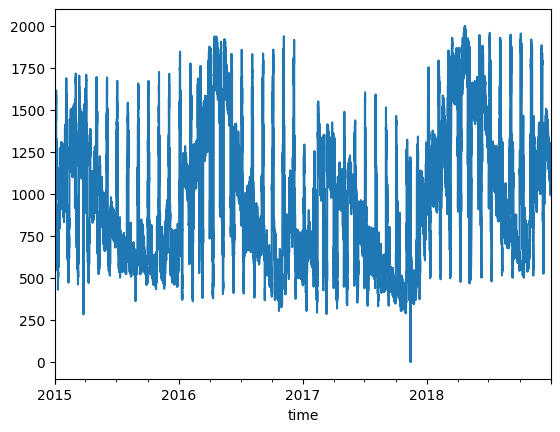

In [7]:
df['generation hydro run-of-river and poundage'].plot()

In [21]:
# frequency를 1단위로 변경
df_day_avg = df.groupby(df.index.astype(str).str.split(' ').str[0]).mean().reset_index()

# 결측치는 가장 최근 과거값과 미래값을 linear interpolation
# 0~1 사이로 표준화
filler = MissingValuesFiller()
scaler = Scaler()
series = scaler.fit_transform(
    filler.transform(TimeSeries.from_dataframe(df=df_day_avg, time_col='time', value_cols=['generation hydro run-of-river and poundage']))
)

In [22]:
series

,generation hydro run-of-river and poundage
time,
2014-12-31,0.454234
2015-01-01,0.458010
2015-01-02,0.613153
2015-01-03,0.662961
2015-01-04,0.729258
...,...
2018-12-27,0.541299
2018-12-28,0.518695
2018-12-29,0.496437


In [24]:
# 학습/검증 데이터 분리
train, val = series.split_after(pd.Timestamp('20170901'))
print(train)
print(val)

            generation hydro run-of-river and poundage
time                                                  
2014-12-31                                    0.454234
2015-01-01                                    0.458010
2015-01-02                                    0.613153
2015-01-03                                    0.662961
2015-01-04                                    0.729258
...                                                ...
2017-08-28                                    0.106744
2017-08-29                                    0.111584
2017-08-30                                    0.102755
2017-08-31                                    0.121423
2017-09-01                                    0.153654

shape: (976, 1, 1), freq: D, size: 7.62 KB
            generation hydro run-of-river and poundage
time                                                  
2017-09-02                                    0.641235
2017-09-03                                    0.589405
2017-09-04           

In [26]:
'''
N-BEATS

- input_chunk_length: lookback period
- output_chunk_length: forecast period
- generic_architecture: (true: generic N-BEATS)/(false: 시계열 분해 N-BEATS)
- num_stacks: stack 수
- num_blocks: block 수
- num_layers: block 내 MLP 층 수(병렬 출력층 이전 MLP)
- layer_widths: num_layers에 지정된 MLP의 노드 수
- trend_polynomial_degree: 시계열 분해 N-BEATS 사용 시, trend와 seasonality 차수
- drop_out: 오버피팅 났을 때 0보다 큰 값을 주어 오버피팅 해소
'''

model_nbeats = NBEATSModel(input_chunk_length=30, output_chunk_length=7)
model_nbeats.fit(train, val_series=val, verbose=True)
pred = model_nbeats.predict(len(val))
print(mape(val, pred))

INFO:pytorch_lightning.utilities.rank_zero:GPU available: False, used: False
INFO:pytorch_lightning.utilities.rank_zero:TPU available: False, using: 0 TPU cores
INFO:pytorch_lightning.utilities.rank_zero:💡 Tip: For seamless cloud logging and experiment tracking, try installing [litlogger](https://pypi.org/project/litlogger/) to enable LitLogger, which logs metrics and artifacts automatically to the Lightning Experiments platform.


┏━━━┳━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━┳━━━━━━━━┳━━━━━━━┳━━━━━━━┓
┃   ┃ Name            ┃ Type             ┃ Params ┃ Mode  ┃ FLOPs ┃
┡━━━╇━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━╇━━━━━━━━╇━━━━━━━╇━━━━━━━┩
│ 0 │ criterion       │ MSELoss          │      0 │ train │     0 │
│ 1 │ train_criterion │ MSELoss          │      0 │ train │     0 │
│ 2 │ val_criterion   │ MSELoss          │      0 │ train │     0 │
│ 3 │ train_metrics   │ MetricCollection │      0 │ train │     0 │
│ 4 │ val_metrics     │ MetricCollection │      0 │ train │     0 │
│ 5 │ stacks          │ ModuleList       │  6.2 M │ train │     0 │
└───┴─────────────────┴──────────────────┴────────┴───────┴───────┘

Trainable params: 6.2 M                                                                                            
Non-trainable params: 1.5 K                                                                                        
Total params: 6.2 M                                                                                                
Total estimated model params size (MB): 49.945                                                                     
Modules in train mode: 396                                                                                         
Modules in eval mode: 0                                                                                            
Total FLOPs: 0

Output()

/usr/local/lib/python3.13/dist-packages/pytorch_lightning/utilities/_pytree.py:21: `isinstance(treespec, LeafSpec)`
is deprecated, use `isinstance(treespec, TreeSpec) and treespec.is_leaf()` instead.

/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py:775: UserWarning: 'pin_memory' argument is 
set as true but no accelerator is found, then device pinned memory won't be used.
  super().__init__(loader)

INFO:pytorch_lightning.utilities.rank_zero:`Trainer.fit` stopped: `max_epochs=100` reached.


INFO:pytorch_lightning.utilities.rank_zero:GPU available: False, used: False
INFO:pytorch_lightning.utilities.rank_zero:TPU available: False, using: 0 TPU cores
INFO:pytorch_lightning.utilities.rank_zero:💡 Tip: For seamless cloud logging and experiment tracking, try installing [litlogger](https://pypi.org/project/litlogger/) to enable LitLogger, which logs metrics and artifacts automatically to the Lightning Experiments platform.


Output()

200.03622793877165


In [ ]:
'''
N-HiTS

- pooling_kernel_sizes: 각 block의 1D max-pooling의 kernel size
- n_freq_downsample: 각 block의 output dimension을 줄여주는(downsampling) 비율(expression rate)
나머지는 N-BEATS와 동일
'''

model_nhits = NHiTSModel(input_chunk_length=30, output_chunk_length=7)
model_nhits.fit(train, val_series=val, verbose=True)
pred_nhits = model_nhits.predict(len(val))
print(mape(val, pred_nhits))

In [27]:
# seasonality 검정
from darts.utils.statistics import check_seasonality

is_weekly_seasonal, weekly_period = check_seasonality(series, m=7, max_lag=60, alpha=0.05)
is_monthly_seasonal, monthly_period = check_seasonality(series, m=30, max_lag=60, alpha=0.05)

print(f'Weekly seasonality: {is_weekly_seasonal} - period={weekly_period}')
print(f'Monthly seasonality: {is_monthly_seasonal} - period={monthly_period}')

Weekly seasonality: False - period=7
Monthly seasonality: True - period=30


In [29]:
# 계절성 공변량 추가
from darts import concatenate
from darts.utils.timeseries_generation import datetime_attribute_timeseries

cov_day = datetime_attribute_timeseries(series.time_index, attribute='day')
cov_month = datetime_attribute_timeseries(series.time_index, attribute='month')
cov = concatenate([cov_day, cov_month], axis='component')
cov

,day,month
time,,
2014-12-31,30.0,11.0
2015-01-01,0.0,0.0
2015-01-02,1.0,0.0
2015-01-03,2.0,0.0
2015-01-04,3.0,0.0
...,...,...
2018-12-27,26.0,11.0
2018-12-28,27.0,11.0
2018-12-29,28.0,11.0


In [31]:
# 공변량 표준화
cov_scaler = Scaler()
scaled_cov = cov_scaler.fit_transform(cov)

INFO:pytorch_lightning.utilities.rank_zero:GPU available: False, used: False
INFO:pytorch_lightning.utilities.rank_zero:TPU available: False, using: 0 TPU cores
INFO:pytorch_lightning.utilities.rank_zero:💡 Tip: For seamless cloud logging and experiment tracking, try installing [litlogger](https://pypi.org/project/litlogger/) to enable LitLogger, which logs metrics and artifacts automatically to the Lightning Experiments platform.


┏━━━┳━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━┳━━━━━━━━┳━━━━━━━┳━━━━━━━┓
┃   ┃ Name            ┃ Type             ┃ Params ┃ Mode  ┃ FLOPs ┃
┡━━━╇━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━╇━━━━━━━━╇━━━━━━━╇━━━━━━━┩
│ 0 │ criterion       │ MSELoss          │      0 │ train │     0 │
│ 1 │ train_criterion │ MSELoss          │      0 │ train │     0 │
│ 2 │ val_criterion   │ MSELoss          │      0 │ train │     0 │
│ 3 │ train_metrics   │ MetricCollection │      0 │ train │     0 │
│ 4 │ val_metrics     │ MetricCollection │      0 │ train │     0 │
│ 5 │ stacks          │ ModuleList       │  6.7 M │ train │     0 │
└───┴─────────────────┴──────────────────┴────────┴───────┴───────┘

Trainable params: 6.7 M                                                                                            
Non-trainable params: 1.8 K                                                                                        
Total params: 6.7 M                                                                                                
Total estimated model params size (MB): 53.738                                                                     
Modules in train mode: 396                                                                                         
Modules in eval mode: 0                                                                                            
Total FLOPs: 0

Output()

/usr/local/lib/python3.13/dist-packages/pytorch_lightning/utilities/_pytree.py:21: `isinstance(treespec, LeafSpec)`
is deprecated, use `isinstance(treespec, TreeSpec) and treespec.is_leaf()` instead.

/usr/local/lib/python3.13/dist-packages/pytorch_lightning/utilities/data.py:106: Total length of `list` across 
ranks is zero. Please make sure this was your intention.

/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py:775: UserWarning: 'pin_memory' argument is 
set as true but no accelerator is found, then device pinned memory won't be used.
  super().__init__(loader)

INFO:pytorch_lightning.utilities.rank_zero:`Trainer.fit` stopped: `max_epochs=100` reached.


INFO:pytorch_lightning.utilities.rank_zero:GPU available: False, used: False
INFO:pytorch_lightning.utilities.rank_zero:TPU available: False, using: 0 TPU cores
INFO:pytorch_lightning.utilities.rank_zero:💡 Tip: For seamless cloud logging and experiment tracking, try installing [litlogger](https://pypi.org/project/litlogger/) to enable LitLogger, which logs metrics and artifacts automatically to the Lightning Experiments platform.


Output()

<Axes: xlabel='time'>

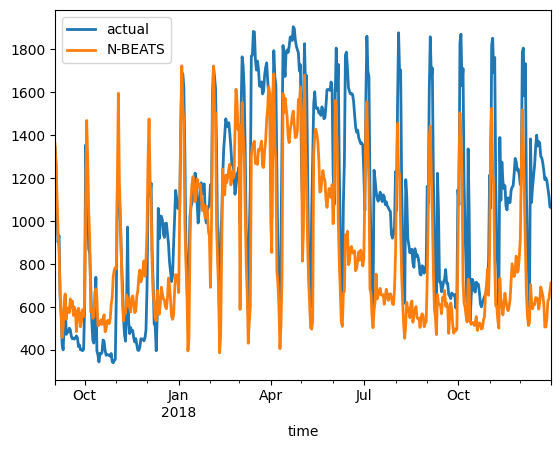

In [32]:
# covariates(공변량) 있는 N-BEATS
nbeats_cov = NBEATSModel(input_chunk_length=30, output_chunk_length=7)
nbeats_cov.fit(train, past_covariates=scaled_cov)
scaled_pred_nbeats_cov = nbeats_cov.predict(past_covariates=scaled_cov, n=len(val))
pred_nbeats_cov = scaler.inverse_transform(scaled_pred_nbeats_cov)
val_re = scaler.inverse_transform(val)
val_re.plot(label='actual')
pred_nbeats_cov.plot(label='N-BEATS')

In [33]:
print(mape(val_re, pred_nbeats_cov))

27.646514992306688


In [ ]:
# covariates(공변량) 있는 N-HiTS
nhits_cov = NHiTSModel(input_chunk_length=30, output_chunk_length=7)
nhits_cov.fit(train, past_covariates=scaled_cov)
scaled_pred_nhits_cov = nhits_cov.predict(past_covariates=scaled_cov, n=len(val))
pred_nhits_cov = scaler.inverse_transform(scaled_pred_nhits_cov)
print(mape(val_re, pred_nhits_cov))